# Held-out calibration and review coverage

Inspect class imbalance and calibrated scores before reading subgroup error rates.

In [1]:
from study import load_cohort, TARGET
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
cohort = load_cohort()
cohort.groupby(TARGET).agg(accounts=(TARGET, 'size'), median_limit_ntd=('LIMIT_BAL', 'median'), median_recent_bill_ntd=('BILL_AMT1', 'median'))

,accounts,median_limit_ntd,median_recent_bill_ntd
default payment next month,,,
0,23364,150000.0,23119.5
1,6636,90000.0,20185.0


In [2]:
report = json.loads(Path('reports/metrics.json').read_text())
pd.DataFrame(report['models']).T[['roc_auc', 'average_precision', 'brier', 'review_rate']].round(3)

,roc_auc,average_precision,brier,review_rate
prevalence,0.500,0.221,0.172,1.000
logistic,0.755,0.508,0.141,0.208
boosting,0.785,0.562,0.134,0.207
boosting + demographics,0.786,0.560,0.133,0.209


In [3]:
groups = pd.DataFrame(report['groups'])
mask = groups.model.eq(report['selected_model'])
groups.loc[mask, ['group', 'size', 'positives', 'review_rate', 'true_positive_rate', 'false_positive_rate']].round(3)

,group,size,positives,review_rate,true_positive_rate,false_positive_rate
10,Sex code 1,2332,573,0.244,0.545,0.146
11,Sex code 2,3668,754,0.183,0.507,0.100
12,Age 21–29,1906,425,0.220,0.532,0.131
13,Age 30–49,3569,770,0.191,0.513,0.103
14,Age 50+,525,132,0.265,0.553,0.168


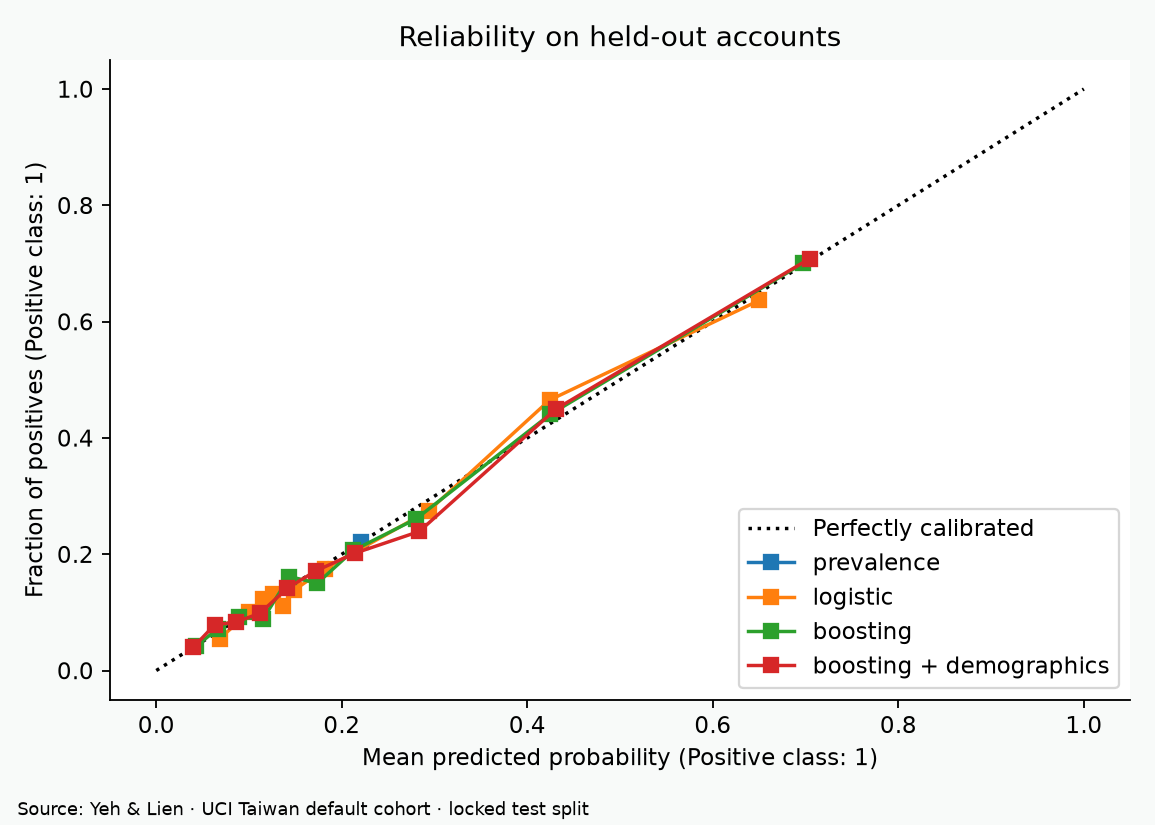

In [4]:
display(Image(filename='reports/figures/calibration.png', width=700))

The review threshold was chosen on the calibration split. A score above the threshold represents inclusion in the benchmark’s review queue. The 2005 cohort supports historical model comparison.